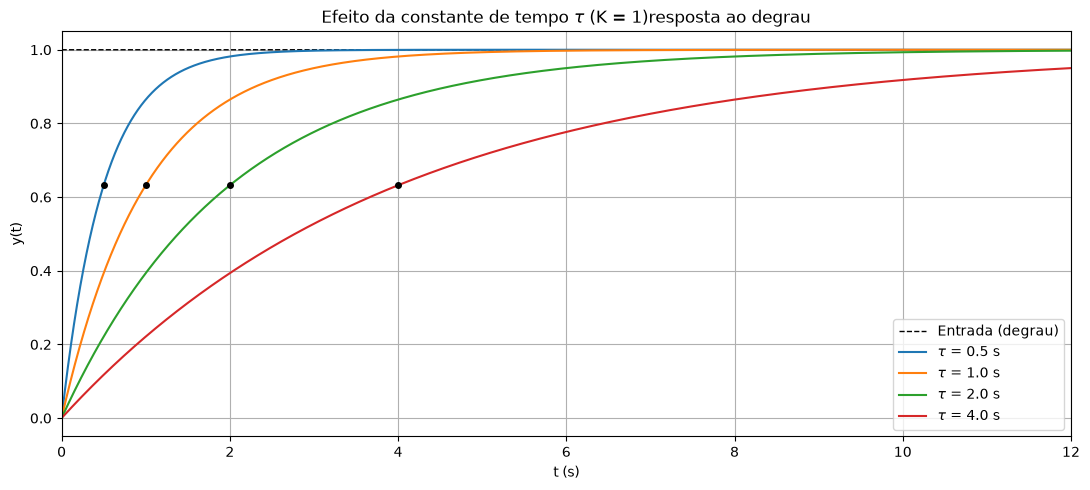

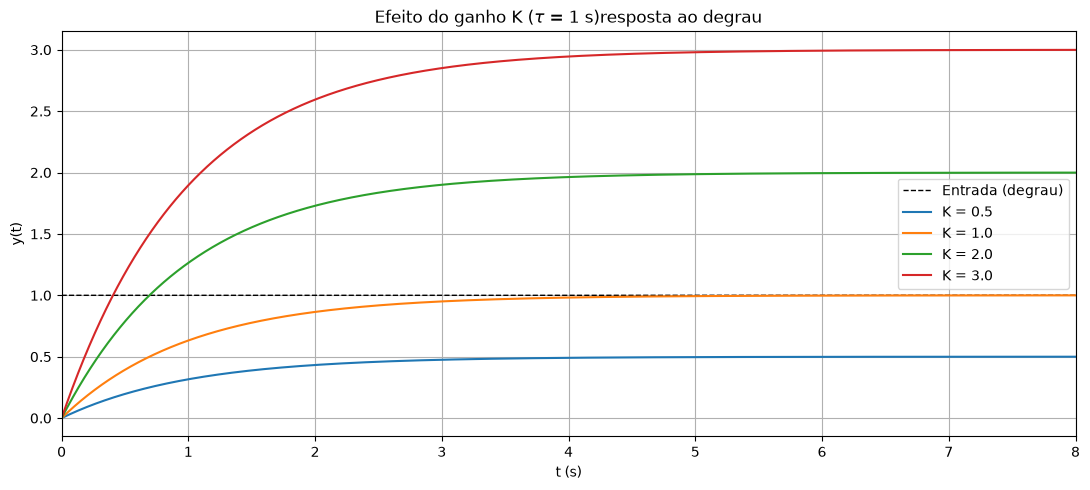

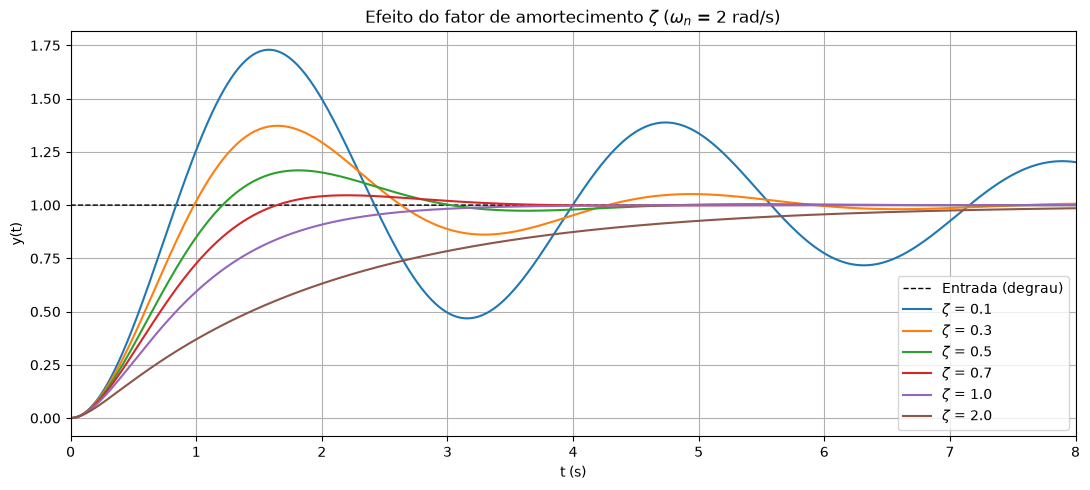

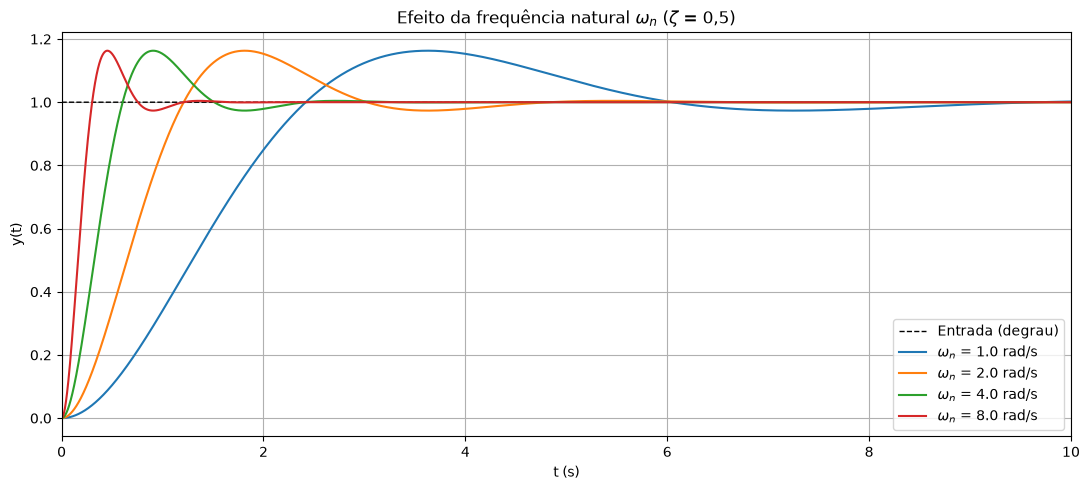

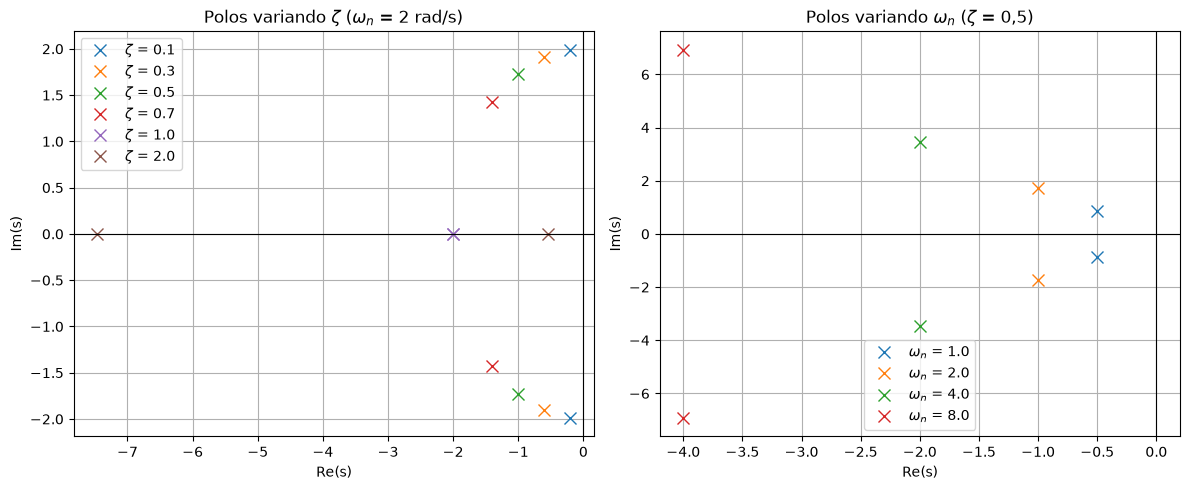

ANÁLISE DO SISTEMA DE PRIMEIRA ORDEM
H(s) = K / (tau*s + 1)

Efeito de tau (K = 1):
 tau (s)      polo   t(63,2%)  ts 2% num.  ts ~ 4*tau
    0.50    -2.000      0.500       1.957       2.000
    1.00    -1.000      1.000       3.913       4.000
    2.00    -0.500      2.000       7.825       8.000
    4.00    -0.250      3.999      15.649      16.000

Efeito de K (tau = 1 s):
       K  valor final   y(t=5tau)
    0.50        0.500      0.4966
    1.00        1.000      0.9933
    2.00        2.000      1.9865
    3.00        3.000      2.9798


ANÁLISE DO SISTEMA DE SEGUNDA ORDEM
H(s) = wn^2 / (s^2 + 2*zeta*wn*s + wn^2)

Efeito de zeta (wn = 2 rad/s):
    zeta                polos    Mp(%)  Mp teor.   tp(s)  tp teor.   tr(s)   ts(s)  ts~4/(z*wn)
    0.10          -0.20±1.99j    72.92     72.92   1.579     1.579   0.552  11.785       20.000
    0.30          -0.60±1.91j    37.23     37.23   1.647     1.647   0.660   5.616        6.667
    0.50          -1.00±1.73j    16.30     16.30   

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURAÇÕES DA SIMULAÇÃO
# ============================================================

dt = 1e-3                              # Passo de tempo (s)

T_FINAL_1 = 20.0                       # Duração para sistemas de 1ª ordem (s)
T_FINAL_2 = 12.0                       # Duração para sistemas de 2ª ordem (s)

t1 = np.arange(0, T_FINAL_1, dt)       # Eixo de tempo (1ª ordem)
t2 = np.arange(0, T_FINAL_2, dt)       # Eixo de tempo (2ª ordem)

# --- Primeira ordem: H(s) = K / (tau*s + 1)
K_FIXO = 1.0                           # Ganho usado no estudo de tau
TAU_FIXO = 1.0                         # Constante de tempo usada no estudo de K
lista_tau = [0.5, 1.0, 2.0, 4.0]       # Valores de tau investigados (s)
lista_K = [0.5, 1.0, 2.0, 3.0]         # Valores de K investigados

# --- Segunda ordem: H(s) = wn^2 / (s^2 + 2*zeta*wn*s + wn^2)
WN_FIXO = 2.0                          # wn usado no estudo de zeta (rad/s)
ZETA_FIXO = 0.5                        # zeta usado no estudo de wn
lista_zeta = [0.1, 0.3, 0.5, 0.7, 1.0, 2.0]
lista_wn = [1.0, 2.0, 4.0, 8.0]        # Valores de wn investigados (rad/s)


# ============================================================
# 2. RESPOSTAS AO DEGRAU (SOLUÇÃO ANALÍTICA)
# ============================================================

def resposta_degrau_1a_ordem(t, K, tau):
    """
    Resposta ao degrau unitário de H(s) = K / (tau*s + 1):

    y(t) = K * (1 - exp(-t/tau))
    """

    return K * (1 - np.exp(-t / tau))


def resposta_degrau_2a_ordem(t, zeta, wn):
    """
    Resposta ao degrau unitário de
    H(s) = wn^2 / (s^2 + 2*zeta*wn*s + wn^2)

    Subamortecido (zeta < 1):
        y(t) = 1 - exp(-zeta*wn*t) * (cos(wd*t) + zeta/sqrt(1-zeta^2) * sin(wd*t))

    Criticamente amortecido (zeta = 1):
        y(t) = 1 - exp(-wn*t) * (1 + wn*t)

    Superamortecido (zeta > 1), com polos p1 e p2 reais:
        y(t) = 1 + (p2*exp(p1*t) - p1*exp(p2*t)) / (p1 - p2)
    """

    if np.isclose(zeta, 1.0):
        y = 1 - np.exp(-wn * t) * (1 + wn * t)

    elif zeta < 1:
        wd = wn * np.sqrt(1 - zeta**2)
        y = 1 - np.exp(-zeta * wn * t) * (
            np.cos(wd * t) + zeta / np.sqrt(1 - zeta**2) * np.sin(wd * t)
        )

    else:
        raiz = np.sqrt(zeta**2 - 1)
        p1 = -wn * (zeta - raiz)
        p2 = -wn * (zeta + raiz)
        y = 1 + (p2 * np.exp(p1 * t) - p1 * np.exp(p2 * t)) / (p1 - p2)

    return y


# ============================================================
# 3. SIMULAÇÃO NUMÉRICA (RUNGE-KUTTA DE 4ª ORDEM)
# ============================================================

def simular_rk4(f, x0, t):
    """
    Integra dx/dt = f(x, u) com entrada degrau unitário (u = 1)
    pelo método de Runge-Kutta de 4ª ordem.
    Retorna a matriz de estados (uma linha por instante de tempo).
    """

    h = t[1] - t[0]
    x = np.zeros((len(t), len(x0)))
    x[0] = x0
    u = 1.0

    for i in range(len(t) - 1):
        k1 = f(x[i], u)
        k2 = f(x[i] + 0.5 * h * k1, u)
        k3 = f(x[i] + 0.5 * h * k2, u)
        k4 = f(x[i] + h * k3, u)
        x[i + 1] = x[i] + (h / 6) * (k1 + 2 * k2 + 2 * k3 + k4)

    return x


def simular_1a_ordem(t, K, tau):
    """
    tau * y' + y = K * u   ->   y' = (K*u - y) / tau
    """

    def f(x, u):
        return np.array([(K * u - x[0]) / tau])

    return simular_rk4(f, np.array([0.0]), t)[:, 0]


def simular_2a_ordem(t, zeta, wn):
    """
    y'' + 2*zeta*wn*y' + wn^2*y = wn^2*u
    Estados: x1 = y, x2 = y'
    """

    def f(x, u):
        return np.array([
            x[1],
            wn**2 * (u - x[0]) - 2 * zeta * wn * x[1]
        ])

    return simular_rk4(f, np.array([0.0, 0.0]), t)[:, 0]


# ============================================================
# 4. POLOS E MÉTRICAS DE DESEMPENHO
# ============================================================

def polos_2a_ordem(zeta, wn):
    """
    Raízes de s^2 + 2*zeta*wn*s + wn^2 = 0:

    p = -zeta*wn ± wn*sqrt(zeta^2 - 1)
    """

    raiz = wn * np.sqrt(complex(zeta**2 - 1))

    return np.array([-zeta * wn + raiz, -zeta * wn - raiz])


def calcular_metricas(t, y, valor_final):
    """
    Calcula, a partir da resposta ao degrau:
    sobressinal (%), tempo de pico, tempo de subida (10% a 90%)
    e tempo de acomodação (critério de 2%).
    """

    sobressinal = max(0.0, (y.max() - valor_final) / valor_final * 100)
    t_pico = t[np.argmax(y)]

    t10 = t[np.argmax(y >= 0.1 * valor_final)]
    t90 = t[np.argmax(y >= 0.9 * valor_final)]
    t_subida = t90 - t10

    fora_da_faixa = np.where(np.abs(y - valor_final) > 0.02 * valor_final)[0]

    if len(fora_da_faixa) == 0:
        t_acomodacao = 0.0
    elif fora_da_faixa[-1] + 1 >= len(t):
        t_acomodacao = np.nan
    else:
        t_acomodacao = t[fora_da_faixa[-1] + 1]

    return sobressinal, t_pico, t_subida, t_acomodacao


# ============================================================
# 5. EFEITO DA CONSTANTE DE TEMPO (TAU) - 1ª ORDEM
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(t1, np.ones_like(t1), "k--", linewidth=1, label="Entrada (degrau)")

for tau in lista_tau:
    y = resposta_degrau_1a_ordem(t1, K_FIXO, tau)
    plt.plot(t1, y, label=rf"$\tau$ = {tau} s")

    # Em t = tau a saída atinge 63,2% do valor final
    plt.plot(tau, 0.632 * K_FIXO, "ko", markersize=4)

plt.xlim(0, 12)

plt.title(r"Efeito da constante de tempo $\tau$ (K = 1)resposta ao degrau")
plt.xlabel("t (s)")
plt.ylabel("y(t)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 6. EFEITO DO GANHO (K) - 1ª ORDEM
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(t1, np.ones_like(t1), "k--", linewidth=1, label="Entrada (degrau)")

for K in lista_K:
    y = resposta_degrau_1a_ordem(t1, K, TAU_FIXO)
    plt.plot(t1, y, label=f"K = {K}")

plt.xlim(0, 8)

plt.title(r"Efeito do ganho K ($\tau$ = 1 s)resposta ao degrau")
plt.xlabel("t (s)")
plt.ylabel("y(t)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. EFEITO DO FATOR DE AMORTECIMENTO (ZETA) - 2ª ORDEM
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(t2, np.ones_like(t2), "k--", linewidth=1, label="Entrada (degrau)")

for zeta in lista_zeta:
    y = resposta_degrau_2a_ordem(t2, zeta, WN_FIXO)
    plt.plot(t2, y, label=rf"$\zeta$ = {zeta}")

plt.xlim(0, 8)

plt.title(r"Efeito do fator de amortecimento $\zeta$ ($\omega_n$ = 2 rad/s)")
plt.xlabel("t (s)")
plt.ylabel("y(t)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. EFEITO DA FREQUÊNCIA NATURAL (WN) - 2ª ORDEM
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(t2, np.ones_like(t2), "k--", linewidth=1, label="Entrada (degrau)")

for wn in lista_wn:
    y = resposta_degrau_2a_ordem(t2, ZETA_FIXO, wn)
    plt.plot(t2, y, label=rf"$\omega_n$ = {wn} rad/s")

plt.xlim(0, 10)

plt.title(r"Efeito da frequência natural $\omega_n$ ($\zeta$ = 0,5)")
plt.xlabel("t (s)")
plt.ylabel("y(t)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. MAPA DE POLOS (PLANO s)
# ============================================================

fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

# Variação de zeta (wn fixo)
for zeta in lista_zeta:
    p = polos_2a_ordem(zeta, WN_FIXO)
    eixos[0].plot(p.real, p.imag, "x", markersize=9, label=rf"$\zeta$ = {zeta}")

eixos[0].set_title(r"Polos variando $\zeta$ ($\omega_n$ = 2 rad/s)")

# Variação de wn (zeta fixo)
for wn in lista_wn:
    p = polos_2a_ordem(ZETA_FIXO, wn)
    eixos[1].plot(p.real, p.imag, "x", markersize=9, label=rf"$\omega_n$ = {wn}")

eixos[1].set_title(r"Polos variando $\omega_n$ ($\zeta$ = 0,5)")

for eixo in eixos:
    eixo.axhline(0, color="k", linewidth=0.8)
    eixo.axvline(0, color="k", linewidth=0.8)
    eixo.set_xlabel("Re(s)")
    eixo.set_ylabel("Im(s)")
    eixo.legend()
    eixo.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 10. ANÁLISE NUMÉRICA - PRIMEIRA ORDEM
# ============================================================

print("ANÁLISE DO SISTEMA DE PRIMEIRA ORDEM")
print("=" * 60)
print("H(s) = K / (tau*s + 1)")

print("\nEfeito de tau (K = 1):")
print(f"{'tau (s)':>8} {'polo':>9} {'t(63,2%)':>10} {'ts 2% num.':>11} {'ts ~ 4*tau':>11}")

for tau in lista_tau:
    y = resposta_degrau_1a_ordem(t1, K_FIXO, tau)
    t63 = t1[np.argmax(y >= 0.632 * K_FIXO)]
    _, _, _, ts = calcular_metricas(t1, y, K_FIXO)

    print(f"{tau:8.2f} {-1/tau:9.3f} {t63:10.3f} {ts:11.3f} {4*tau:11.3f}")

print("\nEfeito de K (tau = 1 s):")
print(f"{'K':>8} {'valor final':>12} {'y(t=5tau)':>11}")

for K in lista_K:
    y = resposta_degrau_1a_ordem(t1, K, TAU_FIXO)
    indice = int(5 * TAU_FIXO / dt)

    print(f"{K:8.2f} {K:12.3f} {y[indice]:11.4f}")


# ============================================================
# 11. ANÁLISE NUMÉRICA - SEGUNDA ORDEM
# ============================================================

def imprimir_tabela_2a_ordem(casos, rotulo):
    print(f"{rotulo:>8} {'polos':>20} {'Mp(%)':>8} {'Mp teor.':>9} "
          f"{'tp(s)':>7} {'tp teor.':>9} {'tr(s)':>7} {'ts(s)':>7} {'ts~4/(z*wn)':>12}")

    for zeta, wn, valor in casos:
        y = resposta_degrau_2a_ordem(t2, zeta, wn)
        mp, tp, tr, ts = calcular_metricas(t2, y, 1.0)
        p = polos_2a_ordem(zeta, wn)

        if abs(p[0].imag) > 1e-9:
            texto_polos = f"{p[0].real:.2f}±{abs(p[0].imag):.2f}j"
        else:
            texto_polos = f"{p[0].real:.2f}, {p[1].real:.2f}"

        if zeta < 1:
            wd = wn * np.sqrt(1 - zeta**2)
            mp_teor = 100 * np.exp(-np.pi * zeta / np.sqrt(1 - zeta**2))
            tp_teor = np.pi / wd
            txt_mp_t = f"{mp_teor:9.2f}"
            txt_tp = f"{tp:7.3f}"
            txt_tp_t = f"{tp_teor:9.3f}"
        else:
            txt_mp_t = f"{'-':>9}"
            txt_tp = f"{'-':>7}"
            txt_tp_t = f"{'-':>9}"

        print(f"{valor:8.2f} {texto_polos:>20} {mp:8.2f} {txt_mp_t} "
              f"{txt_tp} {txt_tp_t} {tr:7.3f} {ts:7.3f} {4/(zeta*wn):12.3f}")


print("\n\nANÁLISE DO SISTEMA DE SEGUNDA ORDEM")
print("=" * 100)
print("H(s) = wn^2 / (s^2 + 2*zeta*wn*s + wn^2)")

print("\nEfeito de zeta (wn = 2 rad/s):")
imprimir_tabela_2a_ordem([(z, WN_FIXO, z) for z in lista_zeta], "zeta")

print("\nEfeito de wn (zeta = 0,5):")
imprimir_tabela_2a_ordem([(ZETA_FIXO, w, w) for w in lista_wn], "wn")


# ============================================================
# 12. VERIFICAÇÃO: SOLUÇÃO ANALÍTICA x SIMULAÇÃO RK4
# ============================================================

print("\n\nVerificação: analítico x Runge-Kutta (erro máximo)")
print("=" * 60)

for tau in lista_tau:
    y_analitico = resposta_degrau_1a_ordem(t1, 1.0, tau)
    y_numerico = simular_1a_ordem(t1, 1.0, tau)
    erro = np.max(np.abs(y_analitico - y_numerico))

    print(f"1ª ordem  tau = {tau:4.1f}           erro = {erro:.3e}")

for zeta in lista_zeta:
    y_analitico = resposta_degrau_2a_ordem(t2, zeta, WN_FIXO)
    y_numerico = simular_2a_ordem(t2, zeta, WN_FIXO)
    erro = np.max(np.abs(y_analitico - y_numerico))

    print(f"2ª ordem  zeta = {zeta:4.1f}, wn = 2   erro = {erro:.3e}")

for wn in lista_wn:
    y_analitico = resposta_degrau_2a_ordem(t2, ZETA_FIXO, wn)
    y_numerico = simular_2a_ordem(t2, ZETA_FIXO, wn)
    erro = np.max(np.abs(y_analitico - y_numerico))

    print(f"2ª ordem  zeta = 0.5, wn = {wn:3.1f}   erro = {erro:.3e}")

print("\nSimulação concluída!")